In [28]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import joblib

In [29]:
df = pd.read_csv("dataset.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (614, 13)


,loan_id,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,loan_status
0,lp001002,male,no,0,graduate,no,5849,0.0,NaN,360.0,1.0,urban,y
1,lp001003,male,yes,1,graduate,no,4583,1508.0,128.0,360.0,1.0,rural,n
2,lp001005,male,yes,0,graduate,yes,3000,0.0,66.0,360.0,1.0,urban,y
3,lp001006,male,yes,0,not graduate,no,2583,2358.0,120.0,360.0,1.0,urban,y
4,lp001008,male,no,0,graduate,no,6000,0.0,141.0,360.0,1.0,urban,y


In [30]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Columns:
['loan_id', 'gender', 'married', 'dependents', 'education', 'self_employed', 'applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history', 'property_area', 'loan_status']

Data Types:
loan_id                  str
gender                   str
married                  str
dependents               str
education                str
self_employed            str
applicantincome        int64
coapplicantincome    float64
loanamount           float64
loan_amount_term     float64
credit_history       float64
property_area            str
loan_status              str
dtype: object

Missing Values:


loan_id               0
gender               13
married               3
dependents           15
education             0
self_employed        32
applicantincome       0
coapplicantincome     0
loanamount           22
loan_amount_term     14
credit_history       50
property_area         0
loan_status           0
dtype: int64


In [31]:
data = df.copy()

data = data.drop(columns=["loan_id"])

print("Remaining Columns:")
print(data.columns.tolist())

Remaining Columns:
['gender', 'married', 'dependents', 'education', 'self_employed', 'applicantincome', 'coapplicantincome', 'loanamount', 'loan_amount_term', 'credit_history', 'property_area', 'loan_status']


In [32]:
data["loan_status"] = data["loan_status"].str.lower().map({
    "y": 1,
    "n": 0
})

data = data.dropna(subset=["loan_status"])

print(data["loan_status"].value_counts())

loan_status
1    422
0    192
Name: count, dtype: int64


In [33]:
categorical_cols = [
    "gender",
    "married",
    "dependents",
    "education",
    "self_employed",
    "property_area"
]

numeric_cols = [
    "applicantincome",
    "coapplicantincome",
    "loanamount",
    "loan_amount_term",
    "credit_history"
]

for col in categorical_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

print("Missing values after cleaning:")
print(data.isnull().sum().sum())

Missing values after cleaning:
0


In [34]:
X = data.drop(columns=["loan_status"])
y = data["loan_status"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

display(X.head())

X Shape: (614, 11)
y Shape: (614,)


,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area
0,male,no,0,graduate,no,5849,0.0,128.0,360.0,1.0,urban
1,male,yes,1,graduate,no,4583,1508.0,128.0,360.0,1.0,rural
2,male,yes,0,graduate,yes,3000,0.0,66.0,360.0,1.0,urban
3,male,yes,0,not graduate,no,2583,2358.0,120.0,360.0,1.0,urban
4,male,no,0,graduate,no,6000,0.0,141.0,360.0,1.0,urban


In [35]:
encoders = {}

for col in categorical_cols:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col].astype(str))
    encoders[col] = encoder

print("Encoded Features:")
display(X.head())

Encoded Features:


,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 491
Testing samples: 123


In [37]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB

In [38]:
categorical_cols = [
    "gender",
    "married",
    "dependents",
    "education",
    "self_employed",
    "property_area"
]

numeric_cols = [
    "applicantincome",
    "coapplicantincome",
    "loanamount",
    "loan_amount_term",
    "credit_history"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        ),
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_cols
        )
    ]
)

In [39]:
X = data.drop(columns=["loan_status"])
y = data["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("naive_bayes", GaussianNB())
])

model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully!")

Gaussian Naive Bayes model trained successfully!


In [40]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Rejected", "Approved"]
    )
)

Accuracy: 0.8455

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.88      0.58      0.70        38
    Approved       0.84      0.96      0.90        85

    accuracy                           0.85       123
   macro avg       0.86      0.77      0.80       123
weighted avg       0.85      0.85      0.84       123



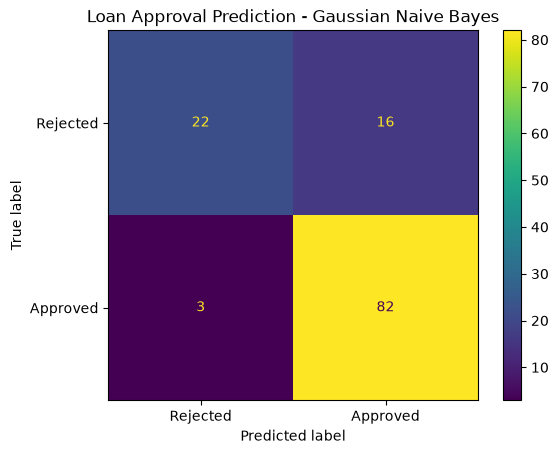

In [41]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)

disp.plot()
plt.title("Loan Approval Prediction - Gaussian Naive Bayes")
plt.show()

In [42]:
joblib.dump(
    model,
    "loan_naive_bayes_model.pkl"
)

print("Model saved successfully!")
print("File: loan_naive_bayes_model.pkl")

Model saved successfully!
File: loan_naive_bayes_model.pkl


var_smoothing=1e-01 → Accuracy=0.6911
var_smoothing=1e-02 → Accuracy=0.6911
var_smoothing=1e-03 → Accuracy=0.6911
var_smoothing=1e-04 → Accuracy=0.6911
var_smoothing=1e-05 → Accuracy=0.6829
var_smoothing=1e-06 → Accuracy=0.6748
var_smoothing=1e-07 → Accuracy=0.6748


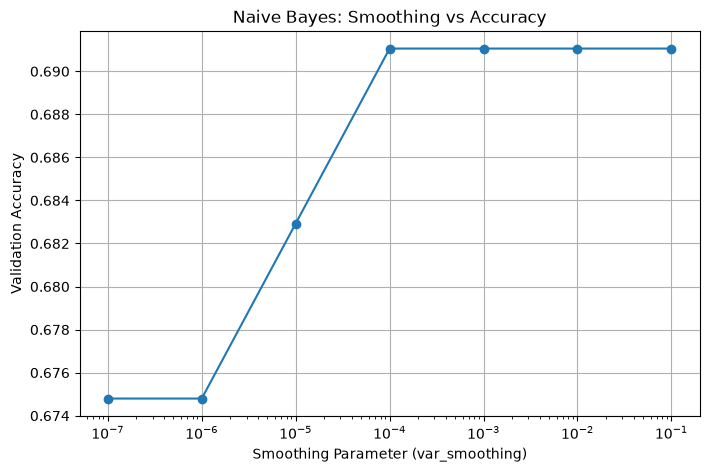

In [43]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

smoothing_values = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7]
accuracies = []

for value in smoothing_values:

    nb_model = Pipeline([
        ("preprocessor", preprocessor),
        ("naive_bayes", GaussianNB(var_smoothing=value))
    ])

    nb_model.fit(X_train, y_train)

    score = nb_model.score(X_test, y_test)
    accuracies.append(score)

for value, score in zip(smoothing_values, accuracies):
    print(f"var_smoothing={value:.0e} → Accuracy={score:.4f}")

plt.figure(figsize=(8, 5))
plt.semilogx(smoothing_values, accuracies, marker="o")
plt.xlabel("Smoothing Parameter (var_smoothing)")
plt.ylabel("Validation Accuracy")
plt.title("Naive Bayes: Smoothing vs Accuracy")
plt.grid(True)
plt.show()

Top 10 features showing the largest class-wise mean difference:


,Feature,Class_0_Mean,Class_1_Mean,Mean_Difference
16,numeric__coapplicantincome,1764.103896,1480.625519,283.478377
15,numeric__applicantincome,5680.545455,5461.201780,219.343674
18,numeric__loan_amount_term,339.584416,342.729970,3.145555
17,numeric__loanamount,146.987013,146.311573,0.675440
19,numeric__credit_history,0.603896,0.982196,0.378300
13,categorical__property_area_semiurban,0.266234,0.424332,0.158099
12,categorical__property_area_rural,0.370130,0.261128,0.109002
8,categorical__education_graduate,0.720779,0.798220,0.077440
9,categorical__education_not graduate,0.279221,0.201780,0.077440
3,categorical__married_yes,0.610390,0.676558,0.066168


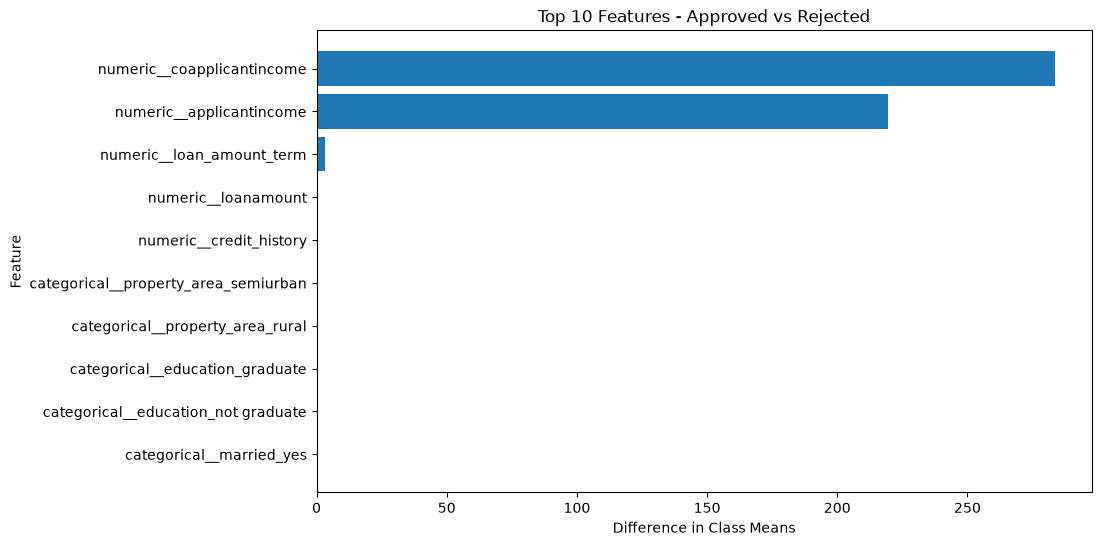

In [44]:
nb = model.named_steps["naive_bayes"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_analysis = pd.DataFrame({
    "Feature": feature_names,
    "Class_0_Mean": nb.theta_[0],
    "Class_1_Mean": nb.theta_[1]
})

feature_analysis["Mean_Difference"] = abs(
    feature_analysis["Class_1_Mean"] -
    feature_analysis["Class_0_Mean"]
)

top_features = feature_analysis.sort_values(
    "Mean_Difference",
    ascending=False
).head(10)

print("Top 10 features showing the largest class-wise mean difference:")
display(top_features)

# Visualization
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Difference"]
)

plt.xlabel("Difference in Class Means")
plt.ylabel("Feature")
plt.title("Top 10 Features - Approved vs Rejected")
plt.gca().invert_yaxis()

plt.show()

In [ ]:
probabilities = model.predict_proba(X_test)

results = X_test.copy()

results["Actual"] = y_test.values
results["Predicted"] = y_pred
results["Rejected_Probability"] = probabilities[:, 0]
results["Approved_Probability"] = probabilities[:, 1]

# Show probability examples
print("Sample Loan Probabilities:")
display(
    results[
        [
            "Actual",
            "Predicted",
            "Rejected_Probability",
            "Approved_Probability"
        ]
    ].head(10)
)

# Find misclassified loans
misclassified = results[
    results["Actual"] != results["Predicted"]
]

print("Number of Misclassified Loans:", len(misclassified))

display(misclassified.head(10))

Sample Loan Probabilities:


,Actual,Predicted,Rejected_Probability,Approved_Probability
150,0,0,0.997011,0.002989
559,1,1,0.014757,0.985243
598,1,1,0.116537,0.883463
235,1,1,0.072888,0.927112
145,1,1,0.033998,0.966002
191,0,1,0.046910,0.953090
557,1,1,0.036823,0.963177
470,1,1,0.034138,0.965862
88,1,1,0.092030,0.907970
386,1,1,0.093948,0.906052


Number of Misclassified Loans: 19


,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,Actual,Predicted,Rejected_Probability,Approved_Probability
191,male,no,0,graduate,no,12000,0.0,164.0,360.0,1.0,semiurban,0,1,0.046910,0.953090
185,male,yes,0,graduate,yes,39147,4750.0,120.0,360.0,1.0,semiurban,1,0,0.952769,0.047231
326,male,no,0,graduate,no,4917,0.0,130.0,360.0,0.0,rural,1,0,0.997017,0.002983
268,female,no,0,graduate,no,3418,0.0,135.0,360.0,1.0,rural,0,1,0.096062,0.903938
479,male,yes,2,graduate,no,2947,1603.0,128.0,360.0,1.0,urban,0,1,0.023443,0.976557
216,male,yes,0,graduate,no,150,1800.0,135.0,360.0,1.0,rural,0,1,0.069327,0.930673
487,male,yes,1,graduate,no,18333,0.0,500.0,360.0,1.0,urban,0,1,0.025348,0.974652
510,male,no,0,not graduate,no,3598,1287.0,100.0,360.0,1.0,rural,0,1,0.257574,0.742426
153,male,yes,2,not graduate,no,2281,0.0,113.0,360.0,1.0,rural,0,1,0.109452,0.890548
34,male,no,3+,graduate,no,12500,3000.0,320.0,360.0,1.0,rural,0,1,0.131963,0.868037


========== ERROR ANALYSIS ==========

Actual vs Predicted:
Predicted   0   1
Actual           
0          22  16
1           3  82

Misclassified Loans:


,gender,married,dependents,education,self_employed,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history,property_area,Actual,Predicted,Rejected_Probability,Approved_Probability
191,male,no,0,graduate,no,12000,0.0,164.0,360.0,1.0,semiurban,0,1,0.046910,0.953090
185,male,yes,0,graduate,yes,39147,4750.0,120.0,360.0,1.0,semiurban,1,0,0.952769,0.047231
326,male,no,0,graduate,no,4917,0.0,130.0,360.0,0.0,rural,1,0,0.997017,0.002983
268,female,no,0,graduate,no,3418,0.0,135.0,360.0,1.0,rural,0,1,0.096062,0.903938
479,male,yes,2,graduate,no,2947,1603.0,128.0,360.0,1.0,urban,0,1,0.023443,0.976557
216,male,yes,0,graduate,no,150,1800.0,135.0,360.0,1.0,rural,0,1,0.069327,0.930673
487,male,yes,1,graduate,no,18333,0.0,500.0,360.0,1.0,urban,0,1,0.025348,0.974652
510,male,no,0,not graduate,no,3598,1287.0,100.0,360.0,1.0,rural,0,1,0.257574,0.742426
153,male,yes,2,not graduate,no,2281,0.0,113.0,360.0,1.0,rural,0,1,0.109452,0.890548
34,male,no,3+,graduate,no,12500,3000.0,320.0,360.0,1.0,rural,0,1,0.131963,0.868037



========== FEATURE CORRELATION ==========


,applicantincome,coapplicantincome,loanamount,loan_amount_term,credit_history
applicantincome,1.000000,-0.116605,0.565181,-0.046531,-0.018615
coapplicantincome,-0.116605,1.000000,0.189218,-0.059383,0.011134
loanamount,0.565181,0.189218,1.000000,0.036960,-0.000607
loan_amount_term,-0.046531,-0.059383,0.036960,1.000000,-0.004705
credit_history,-0.018615,0.011134,-0.000607,-0.004705,1.000000


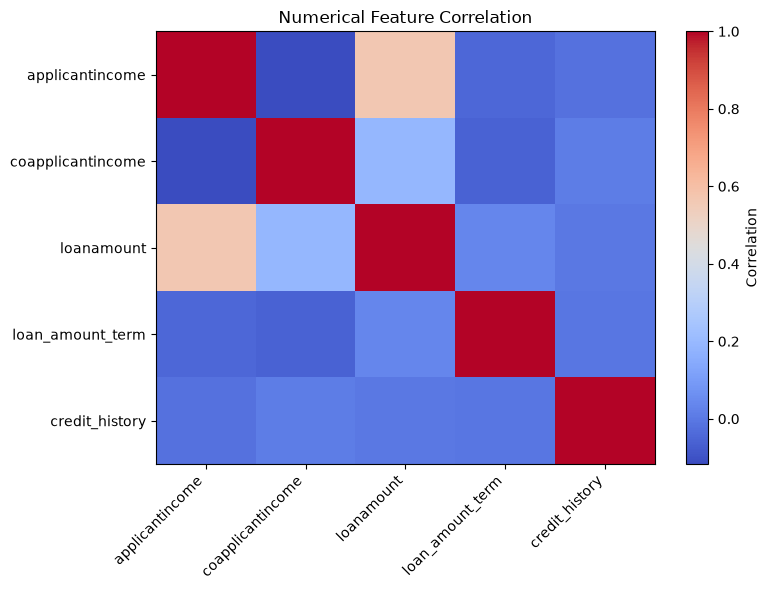


========== NAIVE BAYES LIMITATION ==========

Naive Bayes assumes that features are conditionally independent
given the target class.

However, loan features may be related.

Examples:
- Applicant income and loan amount
- Applicant income and coapplicant income
- Loan amount and loan term

Therefore, the independence assumption may not be completely true
for this loan dataset.

Misclassified loans can occur when multiple correlated features
provide overlapping information or when the applicant falls into
a pattern that the model has not learned well.



In [ ]:

print("========== ERROR ANALYSIS ==========")

print("\nActual vs Predicted:")
print(
    pd.crosstab(
        results["Actual"],
        results["Predicted"],
        rownames=["Actual"],
        colnames=["Predicted"]
    )
)

print("\nMisclassified Loans:")
display(misclassified.head(10))

# Correlation analysis for numerical features
correlation = data[numeric_cols].corr()

print("\n========== FEATURE CORRELATION ==========")
display(correlation)

# Visualization
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")

plt.xticks(
    range(len(numeric_cols)),
    numeric_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numeric_cols)),
    numeric_cols
)

plt.colorbar(label="Correlation")
plt.title("Numerical Feature Correlation")

plt.tight_layout()
plt.show()

print("\n========== NAIVE BAYES LIMITATION ==========")

print("""
Naive Bayes assumes that features are conditionally independent
given the target class.

However, loan features may be related.

Examples:
- Applicant income and loan amount
- Applicant income and coapplicant income
- Loan amount and loan term

Therefore, the independence assumption may not be completely true
for this loan dataset.

Misclassified loans can occur when multiple correlated features
provide overlapping information or when the applicant falls into
a pattern that the model has not learned well.
""")